02 strip pattern: what do the 16 strips of ScoNet-MT actually do?

ScoNet-MT cuts the feature map into **16 horizontal strips** (head ... feet). every strip gets its own classifier, and at test time the 16 answers are **averaged with equal weight**. in checkpoint_1 i saw that strip 7 alone (81.8%) beat the average of all strips (76.8%) at 20k, and that's the reason we want a *learned strip weighting* in the new architecture.

but before building anything, i want to understand the strips themselves. in step 1 i look at which part of the body one strip sees, in step 2 how good every strip is on its own (and if it's the same in all 10 of my models), in step 3 which strip separates which pair of classes, in step 4 if the 16 strips are 16 independent opinions or mostly the same opinion 16 times, in step 5 if the strips agree with each other for one child, in step 6 if every strip has its own "bias" towards a class, and in step 7 how much a perfect strip choice could gain (illustration only).

there's no training here. i only use the logits that my two full runs (official pkl and from-raw pkl, checkpoint_1) saved for the full 1:1:8 test set (749 children), at 5 checkpoints each, so **10 models**. every file has `logits [749, 3, 16]` = (child, class, strip).

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import (load_saved_logits, load_seq, sil_transform, metrics, print_metrics, auc,
                    LABEL_NAMES, ResNet9)

FIG_DIR = os.path.join('output', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


RUNS = ['official', 'fromraw']
ITERS = [12000, 14000, 16000, 18000, 20000]
print('runs:', RUNS, '| checkpoints:', ITERS)

runs: ['official', 'fromraw'] | checkpoints: [12000, 14000, 16000, 18000, 20000]


step 1: which part of the body does one strip see?

the input is `64 x 44`, and ResNet9 has strides 1, 2, 2, 1, so the feature map is `16 x 11` and every feature row belongs to **4 pixel rows** of the input. horizontal pooling turns every feature row into one strip, so strip `k` "sits" on pixel rows `4k ... 4k+3`.

but a feature cell doesn't only look at its own 4 rows, because every 3x3 convolution makes the area it looks at (the **receptive field**) bigger. i compute it with the normal formula, layer by layer: `r` is the receptive field size and `j` the distance between two neighbouring output cells (in input pixels), and for a conv with kernel `k` and stride `s` it's `r = r + (k - 1) * j` and then `j = j * s`. the downsample 1x1 convs in the skip connections don't make it bigger, so i only follow the main 3x3 path.

In [2]:
def receptive_field():
    # (name, kernel, stride) along the main path of ResNet9 (2 convs per BasicBlock)
    layers = [('conv1', 3, 1),
              ('layer1.conv1', 3, 1), ('layer1.conv2', 3, 1),
              ('layer2.conv1', 3, 2), ('layer2.conv2', 3, 1),
              ('layer3.conv1', 3, 2), ('layer3.conv2', 3, 1),
              ('layer4.conv1', 3, 1), ('layer4.conv2', 3, 1)]
    r, j = 1, 1
    for name, k, s in layers:
        r = r + (k - 1) * j
        j = j * s
        print(f'{name:14s} | receptive field {r:3d} px | step between cells {j} px')
    return r, j


rf, step = receptive_field()
print()
print('one strip = 4 pixel rows, but every cell in it looks at', rf, 'pixel rows =', round(100 * rf / 64), '% of the image height')

conv1          | receptive field   3 px | step between cells 1 px
layer1.conv1   | receptive field   5 px | step between cells 1 px
layer1.conv2   | receptive field   7 px | step between cells 1 px
layer2.conv1   | receptive field   9 px | step between cells 2 px
layer2.conv2   | receptive field  13 px | step between cells 2 px
layer3.conv1   | receptive field  17 px | step between cells 4 px
layer3.conv2   | receptive field  25 px | step between cells 4 px
layer4.conv1   | receptive field  33 px | step between cells 4 px
layer4.conv2   | receptive field  41 px | step between cells 4 px

one strip = 4 pixel rows, but every cell in it looks at 41 pixel rows = 64 % of the image height


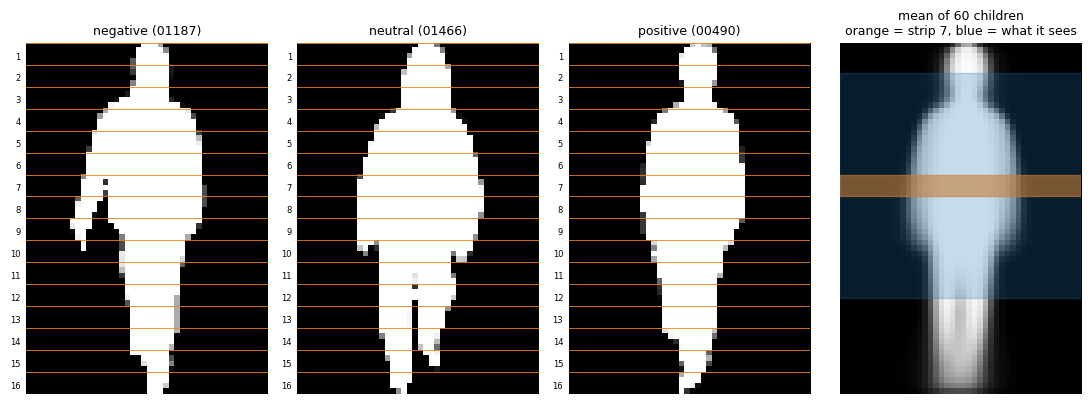

In [3]:
_, true16, subj16 = load_saved_logits('official', 16000)
example = {c: subj16[true16 == c][0] for c in range(3)}
fig, ax = plt.subplots(1, 4, figsize=(11, 5))
for c in range(3):
    seq = sil_transform(load_seq(example[c]))
    ax[c].imshow(seq[len(seq) // 2], cmap='gray')
    for k in range(17):
        ax[c].axhline(4 * k - 0.5, color='tab:orange', lw=0.6)
    for k in range(16):
        ax[c].text(-1.5, 4 * k + 2, str(k + 1), fontsize=6, ha='right', va='center')
    ax[c].set_title(f'{LABEL_NAMES[c]} ({example[c]})', fontsize=9)
    ax[c].axis('off')

# receptive field of strip 7 (rows 24-27), centre ~ row 25.5
mean_sil = np.mean([sil_transform(load_seq(s)).mean(0) for s in subj16[:60]], axis=0)
ax[3].imshow(mean_sil, cmap='gray')
centre = 4 * 6 + 1.5
ax[3].axhspan(4 * 6 - 0.5, 4 * 7 - 0.5, color='tab:orange', alpha=0.6)
ax[3].axhspan(max(-0.5, centre - rf / 2), min(63.5, centre + rf / 2), color='tab:blue', alpha=0.25)
ax[3].set_title('mean of 60 children\norange = strip 7, blue = what it sees', fontsize=9)
ax[3].axis('off')
save_and_show(fig, '01_strips_on_body.png')

one strip "sits" on 4 pixel rows, but every cell in it looks at **41 pixel rows = 64% of the image height**. the receptive field grows fastest in layer3 and layer4, where every 3x3 conv adds 8 px because the step between cells is already 4 px. in the right picture, strip 7 (orange) sits at about the hands / hips, but it sees everything from the shoulders down to the knees (blue).

so "strip = body part" is only roughly true. neighbouring strips share most of their input, and i expect them to be strongly correlated (i check that in step 4). in the 3 examples i still can't see any difference between the classes by eye.

step 2: how good is every strip on its own?

for every strip i take the `argmax` over the 3 classes **of that strip only**, so each strip becomes its own little classifier. then i compute the same metrics as for the whole model (paper convention: Sen = recall of negative, Spe = neutral + positive not called negative). i do this for all 10 models, so i can see if a pattern is stable or just one lucky checkpoint.

In [4]:
models = {}
for run in RUNS:
    for it in ITERS:
        logits, true, subj = load_saved_logits(run, it)
        assert (subj == subj16).all() and (true == true16).all(), 'children in a different order!'
        models[f'{run}@{it // 1000}k'] = logits
true = true16
print(len(models), 'models, logits shape', models['official@16k'].shape)
print('test children per class:', [int((true == c).sum()) for c in range(3)])


def strip_metrics(logits):
    """metrics of every strip alone -> dict of arrays [16]"""
    rows = [metrics(true, logits[:, :, s].argmax(1)) for s in range(16)]
    return {k: np.array([r[k] for r in rows]) for k in ['acc', 'rec_neg', 'rec_neu', 'rec_pos', 'bal']}


per_strip = {name: strip_metrics(lg) for name, lg in models.items()}
avg_all = {name: metrics(true, lg.mean(-1).argmax(1)) for name, lg in models.items()}

m = per_strip['official@16k']
print('official@16k, every strip alone')
print('strip |   acc  rec_neg  rec_neu  rec_pos   bal')
for s in range(16):
    print(f'  {s + 1:2d}  | {m["acc"][s]:5.1f}  {m["rec_neg"][s]:6.1f}  {m["rec_neu"][s]:6.1f}  {m["rec_pos"][s]:6.1f}  {m["bal"][s]:5.1f}')
a = avg_all['official@16k']
print(f' mean | {a["acc"]:5.1f}  {a["rec_neg"]:6.1f}  {a["rec_neu"]:6.1f}  {a["rec_pos"]:6.1f}  {a["bal"]:5.1f}   <- the normal ScoNet decision')

10 models, logits shape (749, 3, 16)
test children per class: [204, 126, 419]
official@16k, every strip alone
strip |   acc  rec_neg  rec_neu  rec_pos   bal
   1  |  70.5    93.1     7.9    78.3   59.8
   2  |  74.9    90.2    15.1    85.4   63.6
   3  |  74.5    86.3    11.1    87.8   61.7
   4  |  77.6    94.6    25.4    85.0   68.3
   5  |  76.8    94.6    38.1    79.7   70.8
   6  |  80.8    91.2    37.3    88.8   72.4
   7  |  82.4    88.2    48.4    89.7   75.5
   8  |  80.4    87.3    46.8    87.1   73.7
   9  |  76.9    91.2    50.8    77.8   73.3
  10  |  78.1    93.6    56.3    77.1   75.7
  11  |  72.6    90.7    54.8    69.2   71.6
  12  |  76.4    89.7    50.0    77.8   72.5
  13  |  62.9    96.6    47.6    51.1   65.1
  14  |  59.8    88.2    69.8    43.0   67.0
  15  |  41.8    86.8    77.8     9.1   57.9
  16  |  43.8    90.2    65.1    14.8   56.7
 mean |  82.6    98.5    40.5    87.6   75.5   <- the normal ScoNet decision


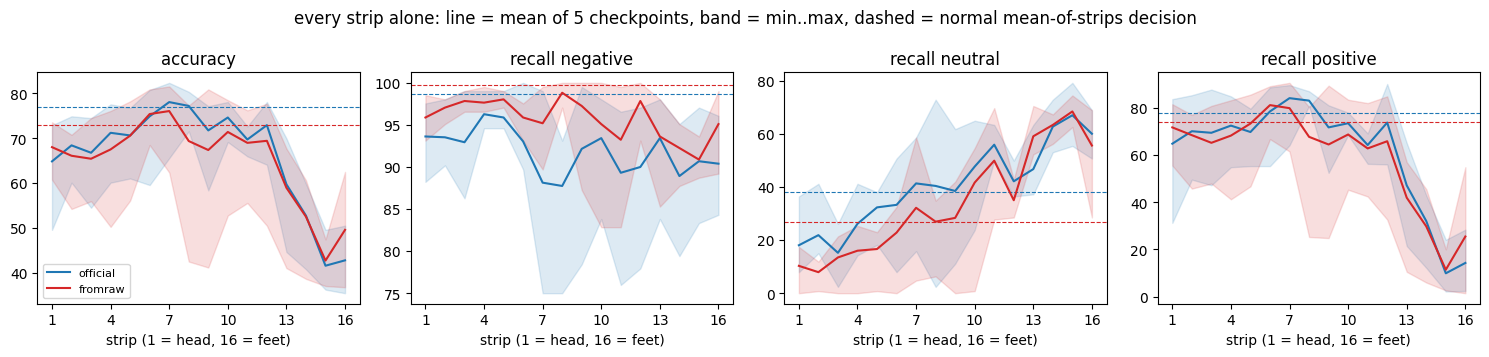

best single strip (by test accuracy) per model: {'official@12k': 7, 'official@14k': 8, 'official@16k': 7, 'official@18k': 7, 'official@20k': 7, 'fromraw@12k': 9, 'fromraw@14k': 6, 'fromraw@16k': 7, 'fromraw@18k': 7, 'fromraw@20k': 7}


In [5]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
x = np.arange(1, 17)
for a, key, title in zip(ax, ['acc', 'rec_neg', 'rec_neu', 'rec_pos'],
                         ['accuracy', 'recall negative', 'recall neutral', 'recall positive']):
    for run, color in zip(RUNS, ['tab:blue', 'tab:red']):
        vals = np.array([per_strip[f'{run}@{it // 1000}k'][key] for it in ITERS])
        a.plot(x, vals.mean(0), color=color, label=run)
        a.fill_between(x, vals.min(0), vals.max(0), color=color, alpha=0.15)
        mean_line = np.mean([avg_all[f'{run}@{it // 1000}k'][key] for it in ITERS])
        a.axhline(mean_line, color=color, ls='--', lw=0.8)
    a.set_title(title)
    a.set_xlabel('strip (1 = head, 16 = feet)')
    a.set_xticks(x[::3])
ax[0].legend(fontsize=8)
fig.suptitle('every strip alone: line = mean of 5 checkpoints, band = min..max, dashed = normal mean-of-strips decision')
save_and_show(fig, '02_strip_alone.png')

best = {name: int(np.argmax(ps['acc'])) + 1 for name, ps in per_strip.items()}
print('best single strip (by test accuracy) per model:', best)

**strip 7 alone (82.4) is almost as good as the mean of all 16 (82.6) at 16k.** strip 7 is the best single strip in 7 of the 10 models, and the other 3 pick strip 6, 8 or 9, so the best area (middle of the body) is stable and not one lucky checkpoint.

**the neutral recall goes up from head to feet**: strips 1-3 only get 8-15%, strips 14-16 get 65-78%. but the feet strips pay for it with positive recall (strip 15: 9.1%), they call almost everybody with scoliosis "neutral". and **the mean of all strips has a neutral recall of 40.5, which is lower than 10 of the 16 single strips.** averaging gives the best negative recall (98.5, no single strip reaches it), but it hides the neutral evidence.

the 10-model bands are wide for neutral (the run is unstable there, like in the old notebook 03) and narrow for negative.

step 3: which strip separates which pair of classes?

the accuracy of one strip mixes two things: (a) can the strip **rank** the children correctly, and (b) is its **decision border** in the right place. in the old notebook 03 i found that for neutral vs negative the ranking was very good (AUC 0.95) and the border was the problem.

so here i only look at the ranking, per strip and per pair of classes. for the pair (A vs B) and strip `s`, the score of a child is `z_A[s] - z_B[s]`, and the AUC is the chance that a random A child gets a higher score than a random B child. 0.5 = coin flip, 1.0 = perfect ranking, and the border doesn't matter for the AUC.

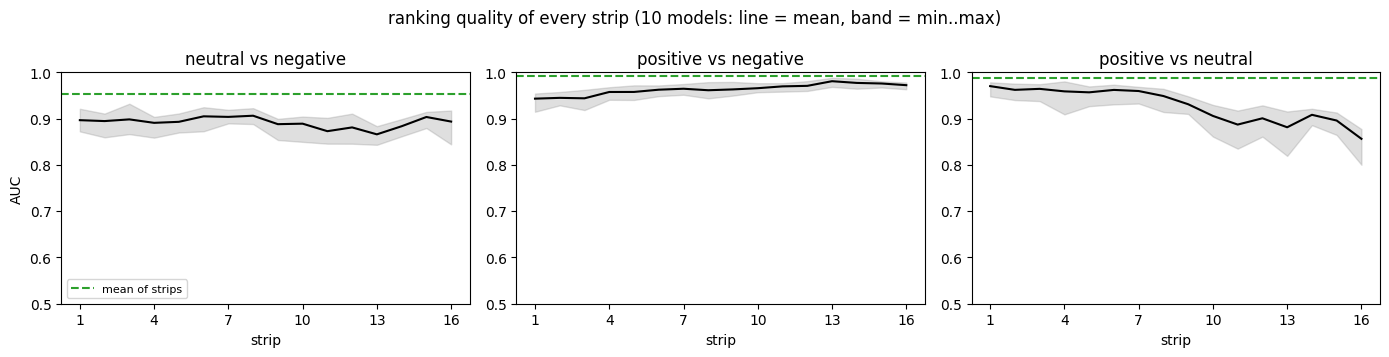

neutral vs negative    | best strip  8 (AUC 0.906) | worst strip 13 (AUC 0.866) | mean of strips 0.953
positive vs negative   | best strip 13 (AUC 0.981) | worst strip  1 (AUC 0.943) | mean of strips 0.991
positive vs neutral    | best strip  1 (AUC 0.970) | worst strip 16 (AUC 0.856) | mean of strips 0.988


In [6]:
PAIRS = [(1, 0, 'neutral vs negative'), (2, 0, 'positive vs negative'), (2, 1, 'positive vs neutral')]


def strip_auc(logits, a, b):
    """AUC of every strip for 'class a vs class b' + the AUC of the mean over strips."""
    per = []
    for s in range(16):
        score = logits[:, a, s] - logits[:, b, s]
        per.append(auc(score[true == a], score[true == b]))
    score = logits[:, a].mean(-1) - logits[:, b].mean(-1)
    return np.array(per), auc(score[true == a], score[true == b])


fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
auc_table = {}
for a_, (ca, cb, title) in zip(ax, PAIRS):
    rows = []
    for name, lg in models.items():
        per, mean_auc = strip_auc(lg, ca, cb)
        rows.append(per)
        auc_table[(name, title)] = (per, mean_auc)
    rows = np.array(rows)
    a_.plot(x, rows.mean(0), color='k')
    a_.fill_between(x, rows.min(0), rows.max(0), color='gray', alpha=0.25)
    a_.axhline(np.mean([auc_table[(n, title)][1] for n in models]), color='tab:green', ls='--', label='mean of strips')
    a_.set_title(title)
    a_.set_xlabel('strip')
    a_.set_ylim(0.5, 1.0)
    a_.set_xticks(x[::3])
ax[0].set_ylabel('AUC')
ax[0].legend(fontsize=8)
fig.suptitle('ranking quality of every strip (10 models: line = mean, band = min..max)')
save_and_show(fig, '03_strip_auc.png')

for ca, cb, title in PAIRS:
    per = np.array([auc_table[(n, title)][0] for n in models]).mean(0)
    mean_auc = np.mean([auc_table[(n, title)][1] for n in models])
    print(f'{title:22s} | best strip {np.argmax(per) + 1:2d} (AUC {per.max():.3f}) | worst strip {np.argmin(per) + 1:2d} '
          f'(AUC {per.min():.3f}) | mean of strips {mean_auc:.3f}')

**every single strip ranks worse than the mean of the 16 strips, for all 3 pairs.** for neutral vs negative the best strip (8) has 0.906 and the mean of the strips 0.953, so averaging DOES help the ranking: the strips carry information that adds up.

**every pair has a different best strip.** for neutral vs negative it's strip 8 (middle of the body), for positive vs negative strip 13 (0.981, legs), and for positive vs neutral strip 1 (0.970, head / shoulders), where the feet are the worst (strip 16, 0.856).

this connects to step 2. strip 13 has a positive recall of only 51%, yet it ranks positive vs negative better than any other strip, so the ranking is there but the border is in the wrong place. that's the same story as for neutral in the old notebook 03, now at the level of a single strip. for neutral vs negative the strips only differ between 0.866 and 0.906, so no strip is "the neutral strip".

step 4: 16 independent opinions, or one opinion 16 times?

if the strips were independent, averaging 16 of them would remove a lot of noise. if they're strongly correlated, averaging does almost nothing and a learned weighting can only gain a little.

for every child and every strip i take the **neutral-vs-negative margin** `z_neu[s] - z_neg[s]`, and then the correlation between the strips over all 749 children (`np.corrcoef`, a library function). to turn the correlation matrix into one number i use the **effective number of strips**: with the eigenvalues `l_1 ... l_16` of the correlation matrix, `n_eff = (sum l)^2 / sum(l^2)`. if all strips are the same, there is one eigenvalue of 16 and `n_eff = 1`, and if they're completely independent, all eigenvalues are 1 and `n_eff = 16`.

neutral vs negative    | n_eff 2.30 | first 3 eigenvalues [10.14  2.68  0.84] | mean correlation of neighbours 0.84
positive vs negative   | n_eff 1.56 | first 3 eigenvalues [12.72  1.47  0.58] | mean correlation of neighbours 0.91
positive vs neutral    | n_eff 2.15 | first 3 eigenvalues [10.65  1.91  1.09] | mean correlation of neighbours 0.84


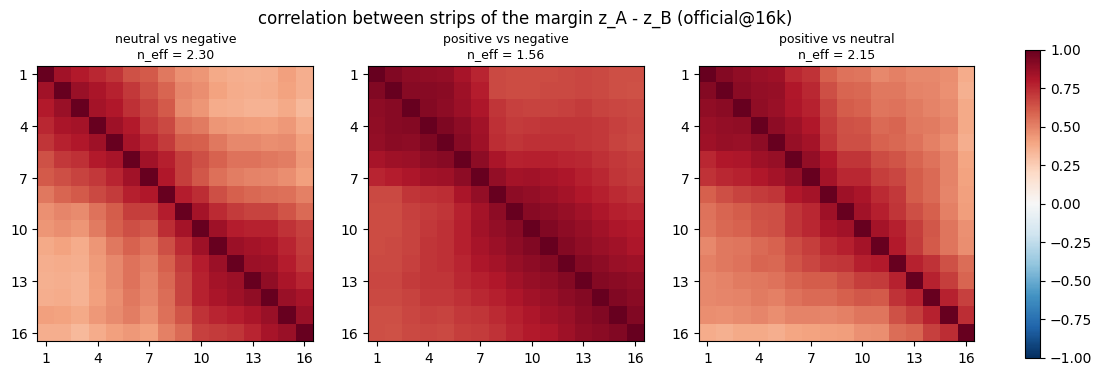

n_eff (neutral vs negative) over the 10 models: min 2.07 max 2.57


In [7]:
def effective_number(corr):
    eig = np.linalg.eigvalsh(corr)
    return eig.sum() ** 2 / (eig ** 2).sum(), eig[::-1]


fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a_, (ca, cb, title) in zip(ax, PAIRS):
    margin = models['official@16k'][:, ca] - models['official@16k'][:, cb]      # [749, 16]
    corr = np.corrcoef(margin.T)
    n_eff, eig = effective_number(corr)
    im = a_.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    a_.set_title(f'{title}\nn_eff = {n_eff:.2f}', fontsize=9)
    a_.set_xticks(range(0, 16, 3), range(1, 17, 3))
    a_.set_yticks(range(0, 16, 3), range(1, 17, 3))
    print(f'{title:22s} | n_eff {n_eff:.2f} | first 3 eigenvalues {np.round(eig[:3], 2)} | '
          f'mean correlation of neighbours {np.mean([corr[s, s + 1] for s in range(15)]):.2f}')
fig.colorbar(im, ax=ax, fraction=0.02)
fig.suptitle('correlation between strips of the margin z_A - z_B (official@16k)')
plt.savefig(os.path.join(FIG_DIR, '04_strip_correlation.png'), dpi=120)
plt.show()

n_effs = []
for name, lg in models.items():
    n_effs.append(effective_number(np.corrcoef((lg[:, 1] - lg[:, 0]).T))[0])
print('n_eff (neutral vs negative) over the 10 models: min', round(min(n_effs), 2), 'max', round(max(n_effs), 2))

**the 16 strips behave like about 2 opinions, not 16**: `n_eff` is 2.30 (neutral vs negative), 1.56 (positive vs negative) and 2.15 (positive vs neutral), and it's stable over the 10 models (2.07-2.57). the matrices show **two blocks**, strips 1-8 (upper body) and strips 9-16 (legs), with neighbours correlated 0.84-0.91, which fits the 41 px receptive field of step 1. for positive vs negative almost everything is one block (first eigenvalue 12.7 of 16), the whole body says the same thing.

what this means for a learned strip weighting: 16 weights per class look like many free numbers, but there are only ~2 independent directions. a weighting can mostly choose "how much upper body vs how much legs", so i shouldn't expect a huge gain.

step 5: do the strips agree for one child?

for every child i count how many of the 16 strips vote for each class (`argmax` per strip), and then i ask two questions: for how many children are all 16 strips unanimous? and for the neutral children, how many strips say "neutral"? if a neutral child usually has e.g. 5 neutral strips and 11 negative strips, then the information is there, but the mean washes it out.

all 16 strips agree for 147 of 749 children = 19.6 %
true negative | mean votes neg / neu / pos = [14.5  0.6  0.9] | unanimous  57.4 %
true neutral  | mean votes neg / neu / pos = [7.6 7.  1.4] | unanimous   6.3 %
true positive | mean votes neg / neu / pos = [ 2.6  2.4 11. ] | unanimous   5.3 %
official@16k
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
mean of strips (normal)            82.6     98.5     77.8     98.5     40.5     87.6     75.5
majority vote of strips            82.8     97.5     78.9     97.5     43.7     87.4     76.2


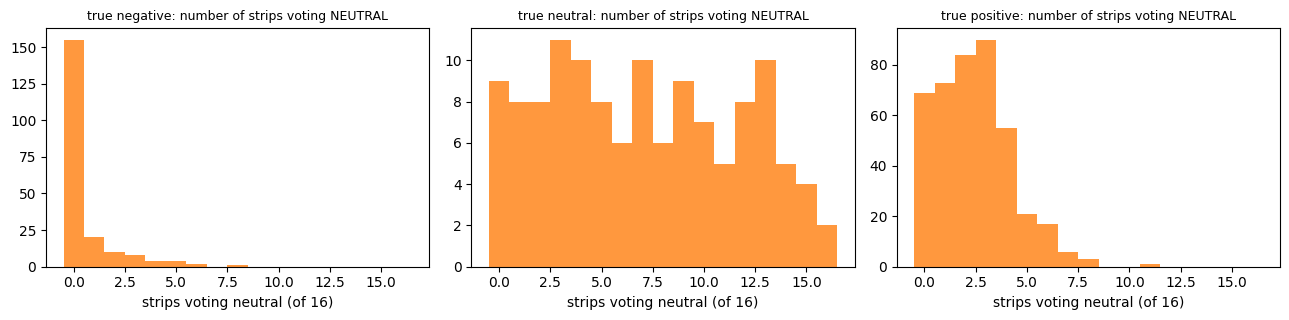

In [8]:
lg = models['official@16k']
votes = np.zeros((len(true), 3), dtype=int)
for i in range(len(true)):
    for s in range(16):
        votes[i, lg[i, :, s].argmax()] += 1

unanimous = (votes.max(1) == 16)
print('all 16 strips agree for', unanimous.sum(), 'of', len(true), 'children =', round(100 * unanimous.mean(), 1), '%')
for c in range(3):
    sel = true == c
    print(f'true {LABEL_NAMES[c]:8s} | mean votes neg / neu / pos = {np.round(votes[sel].mean(0), 1)} '
          f'| unanimous {100 * unanimous[sel].mean():5.1f} %')

majority = votes.argmax(1)
print_metrics([('mean of strips (normal)', metrics(true, lg.mean(-1).argmax(1))),
               ('majority vote of strips', metrics(true, majority))], 'official@16k')

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for c in range(3):
    sel = true == c
    ax[c].hist(votes[sel, 1], bins=np.arange(18) - 0.5, color='tab:orange', alpha=0.8)
    ax[c].set_title(f'true {LABEL_NAMES[c]}: number of strips voting NEUTRAL', fontsize=9)
    ax[c].set_xlabel('strips voting neutral (of 16)')
save_and_show(fig, '05_neutral_votes.png')

only 19.6% of the children get the same vote from all 16 strips. negatives are the clearest: on average 14.5 of 16 strips say negative, and 57% are unanimous. **neutral children are split right down the middle: on average 7.6 strips say negative and 7.0 say neutral.** so for a typical neutral child almost half of the strips already "see" neutral, but the other half (and the mean) pull it to negative.

the majority vote is basically the same as the mean (82.8 vs 82.6, neutral 43.7 vs 40.5). so how the 16 strip votes are combined matters less than *which* strips get how much say.

step 6: does every strip have its own bias?

the BNNeck logits are cosines, so every strip can sit at a different "level" for every class. if, e.g., the feet strips always give neutral a bit more, they push every child towards neutral, no matter what the child looks like. that's a per-strip **bias**, and a learned weighting (or a per-strip offset) could remove it.

i compute the mean logit of every class in every strip, separately for the 3 true classes, and then i subtract the mean over the 3 classes, so i only see which class a strip prefers.

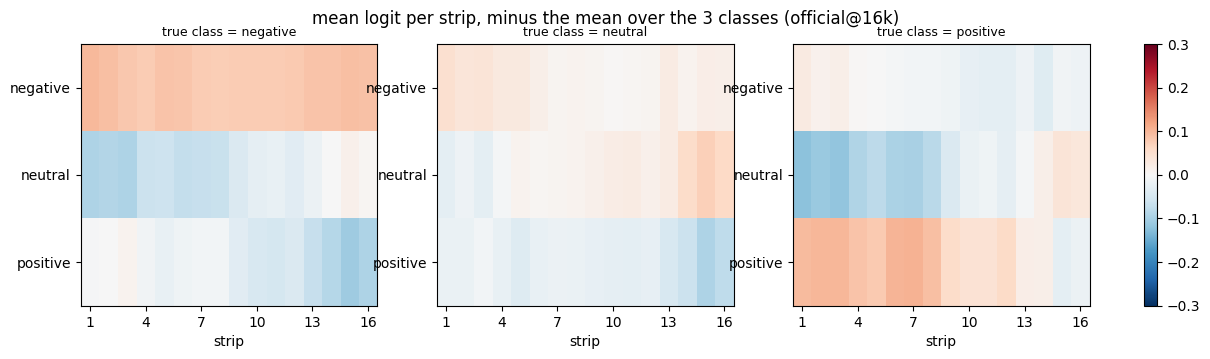

strip | preference over all 749 children (neg / neu / pos)
   1  | +0.051 -0.099 +0.049
   2  | +0.038 -0.090 +0.051
   3  | +0.039 -0.096 +0.057
   4  | +0.027 -0.069 +0.041
   5  | +0.028 -0.059 +0.032
   6  | +0.022 -0.071 +0.049
   7  | +0.017 -0.071 +0.054
   8  | +0.017 -0.062 +0.045
   9  | +0.016 -0.033 +0.018
  10  | +0.008 -0.015 +0.007
  11  | +0.006 -0.010 +0.004
  12  | +0.006 -0.021 +0.016
  13  | +0.019 -0.003 -0.016
  14  | +0.005 +0.020 -0.024
  15  | +0.023 +0.038 -0.060
  16  | +0.018 +0.030 -0.048


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for c in range(3):
    mean_z = lg[true == c].mean(0)                       # [3 classes, 16 strips]
    mean_z = mean_z - mean_z.mean(0, keepdims=True)      # which class does the strip prefer
    im = ax[c].imshow(mean_z, cmap='RdBu_r', vmin=-0.3, vmax=0.3, aspect='auto')
    ax[c].set_yticks(range(3), LABEL_NAMES)
    ax[c].set_xticks(range(0, 16, 3), range(1, 17, 3))
    ax[c].set_title(f'true class = {LABEL_NAMES[c]}', fontsize=9)
    ax[c].set_xlabel('strip')
fig.colorbar(im, ax=ax, fraction=0.02)
fig.suptitle('mean logit per strip, minus the mean over the 3 classes (official@16k)')
plt.savefig(os.path.join(FIG_DIR, '06_strip_bias.png'), dpi=120)
plt.show()

# the 'bias' that a strip has for ALL children together (prior of the strip)
all_bias = lg.mean(0) - lg.mean(0).mean(0, keepdims=True)
print('strip | preference over all 749 children (neg / neu / pos)')
for s in range(16):
    print(f'  {s + 1:2d}  | {all_bias[0, s]:+.3f} {all_bias[1, s]:+.3f} {all_bias[2, s]:+.3f}')

over all children, **strips 1-8 put neutral 0.06-0.10 below the class mean, while strips 14-16 put it 0.02-0.04 above.** the logits are cosines and the loss multiplies them by 16, so 0.1 cosine = 1.6 in softmax units, which is a big push.

careful: this "preference" also contains the class mix of the test set (only 17% are neutral), so the absolute level is not pure bias. but all strips see the same children, so the **difference between the strips** is fair, and the upper body is clearly more anti-neutral than the legs. together with steps 2 and 5: the legs give neutral much more often mainly because their border for neutral sits lower, not because they rank better (their neutral vs negative AUC is not higher, step 3).

step 7: how much could a perfect strip choice gain? (illustration only)

here i **cheat on purpose**: i choose the strips using the test set, so these numbers are not results. they only show the *upper limit* of what a strip choice could give, so i know if a learned strip weighting is worth the effort (in notebook 03 i do it honestly, choosing on one part and testing on another part). i compare three choices: the best single strip, the best window of neighbouring strips (start, length), and the normal mean of all 16 strips.

In [10]:
def best_window(logits):
    best = (0, None)
    for start in range(16):
        for end in range(start + 1, 17):
            acc = metrics(true, logits[:, :, start:end].mean(-1).argmax(1))['acc']
            if acc > best[0]:
                best = (acc, (start + 1, end))
    return best


print(f'{"model":14s} | {"mean of 16":>10s} | {"best strip":>14s} | {"best window":>18s}')
for name, lg_ in models.items():
    acc_all = avg_all[name]['acc']
    s = int(np.argmax(per_strip[name]['acc']))
    w_acc, w = best_window(lg_)
    print(f'{name:14s} | {acc_all:10.1f} | {per_strip[name]["acc"][s]:6.1f} (strip {s + 1:2d}) | {w_acc:6.1f} (strips {w[0]:2d}-{w[1]:2d})')

model          | mean of 16 |     best strip |        best window
official@12k   |       82.2 |   80.0 (strip  7) |   84.9 (strips  4-13)
official@14k   |       64.1 |   71.6 (strip  8) |   72.8 (strips 10-11)
official@16k   |       82.6 |   82.4 (strip  7) |   85.6 (strips  4-14)
official@18k   |       78.6 |   80.6 (strip  7) |   82.2 (strips  4-14)
official@20k   |       76.8 |   81.8 (strip  7) |   82.1 (strips  6- 8)
fromraw@12k    |       77.6 |   80.9 (strip  9) |   83.6 (strips  6-12)
fromraw@14k    |       53.8 |   74.0 (strip  6) |   74.0 (strips  6- 6)


fromraw@16k    |       80.4 |   81.6 (strip  7) |   83.6 (strips  4-13)
fromraw@18k    |       78.6 |   79.6 (strip  7) |   80.8 (strips  6- 7)
fromraw@20k    |       74.8 |   78.0 (strip  7) |   78.8 (strips  6- 7)


at the good checkpoints a perfect window gains about +3 points (16k: 82.6 -> 85.6 with strips 4-14), and that's an **upper limit**, because the window was chosen on the test set. **the big differences are at the bad checkpoints**: official@14k 64.1 -> 72.8 and fromraw@14k 53.8 -> 74.0 (strip 6 alone!). when the mean collapses, some single strips are still fine.

so a good strip weighting may help **stability** more than it helps the best peak number. that's useful, because in checkpoint_1 the accuracy jumped a lot between checkpoints.

step 8: analysis

**1. is one strip one body part?**

only roughly. every strip sees 41 of 64 rows, and neighbours are correlated 0.84-0.91. the 16 strips are really about 2 groups: upper body (1-8) and legs (9-16).

**2. why is the mean so bad for neutral, when many single strips are good at it?**

the 8 upper strips have a strong anti-neutral bias (step 6), and the legs that do say neutral also call almost all positives neutral (step 2). so equal averaging is a compromise in which the neutral votes of the legs are outvoted. for a typical neutral child the vote is 7.6 vs 7.0 (step 5), so it's very close.

**3. should we throw strips away?**

no. the mean of the strips ranks better than every single strip, for all 3 pairs (step 3). the strips add information, the problem is their weights and their borders.

**4. does a weighting need to be different per class?**

yes, probably. the best strip is different for every pair of classes: 8 for neutral vs negative, 13 for positive vs negative, 1 for positive vs neutral, and one shared weight per strip can't follow that.

**5. what is realistic to gain?**

at good checkpoints at most ~3 points (chosen on test, so less in reality), but at bad checkpoints much more (+9 to +20), so the main value could be stability.

**6. what are the limitations?**

- all numbers are on the **test set**, and step 7 chooses strips on the test set, so it's an illustration, not a result.
- only one architecture (ScoNet-MT with natural sampling). with a balanced sampler or another loss the roles of the strips could change.
- the per-strip AUC only uses the margin between 2 classes and ignores the third class.
- the receptive field of 41 px is the theoretical maximum. the *effective* receptive field is usually smaller and weighted towards the centre.
- the "preference" in step 6 mixes real bias with the class mix of the test set, only the differences between strips are fair.
- the tables are for `official@16k`, the plots show the band over 10 models.

what can we absorb into the new architecture?

first, **keep all 16 strips, but learn per-class strip weights** (3 x 16 numbers, softmax so they stay positive and sum to 1). the idea comes from steps 3 and 4, and notebook 03 tests it honestly. because n_eff is about 2, i also want to **try a cheap 2-group version** (upper 1-8 vs legs 9-16, 3 x 2 weights), because if it's as good as 3 x 16 the simple one is better for a paper (fewer parameters, less overfitting).

second, **fix the border, not only the weights**: a per-class offset (logit adjustment, notebook 01) is needed in any case, because the neutral problem is mainly the border (steps 2 and 6). and third, **report stability**: compare the methods over several checkpoints (and seeds), not only at the best checkpoint, because step 7 suggests that this is where strip weighting helps most.